In [53]:
import pandas as pd
import matplotlib as plt
df1 = pd.read_csv("data\\salesdaily.csv")
print(df1.head())

      datum  M01AB  M01AE  N02BA  N02BE  N05B  N05C   R03  R06  Year  Month  \
0  1/2/2014    0.0   3.67    3.4  32.40   7.0   0.0   0.0  2.0  2014      1   
1  1/3/2014    8.0   4.00    4.4  50.60  16.0   0.0  20.0  4.0  2014      1   
2  1/4/2014    2.0   1.00    6.5  61.85  10.0   0.0   9.0  1.0  2014      1   
3  1/5/2014    4.0   3.00    7.0  41.10   8.0   0.0   3.0  0.0  2014      1   
4  1/6/2014    5.0   1.00    4.5  21.70  16.0   2.0   6.0  2.0  2014      1   

   Hour Weekday Name  
0   248     Thursday  
1   276       Friday  
2   276     Saturday  
3   276       Sunday  
4   276       Monday  


In [54]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   str    
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   str    
dtypes: float64(8), int64(3), str(2)
memory usage: 247.1 KB


In [55]:
df1['datum'] = pd.to_datetime(df1['datum'])

In [56]:
df1.info()


<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   datum         2106 non-null   datetime64[us]
 1   M01AB         2106 non-null   float64       
 2   M01AE         2106 non-null   float64       
 3   N02BA         2106 non-null   float64       
 4   N02BE         2106 non-null   float64       
 5   N05B          2106 non-null   float64       
 6   N05C          2106 non-null   float64       
 7   R03           2106 non-null   float64       
 8   R06           2106 non-null   float64       
 9   Year          2106 non-null   int64         
 10  Month         2106 non-null   int64         
 11  Hour          2106 non-null   int64         
 12  Weekday Name  2106 non-null   str           
dtypes: datetime64[us](1), float64(8), int64(3), str(1)
memory usage: 228.7 KB


In [57]:
drug_names = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']

In [58]:
df_res = pd.DataFrame()
df_res['total_sales'] = df1[drug_names].sum()

print('Total Sales for eacj Drug catgegory')
df_res['total_sales']


Total Sales for eacj Drug catgegory


M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
N02BE    63005.402708
N05B     18645.737500
N05C      1249.958333
R03      11608.822917
R06       6107.817500
Name: total_sales, dtype: float64

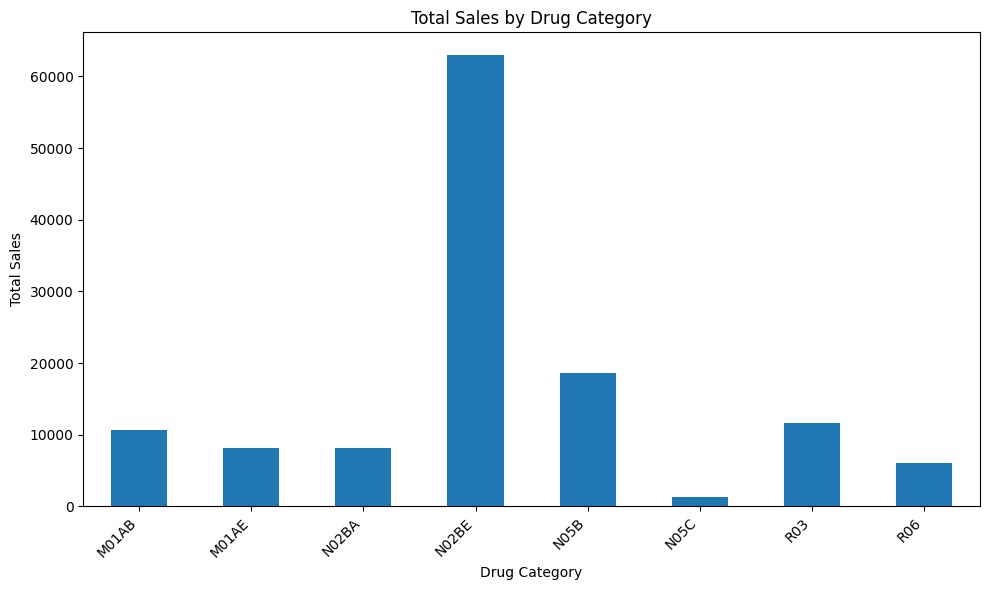

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
df_res['total_sales'].plot(kind='bar')
plt.title('Total Sales by Drug Category')  # Fixed spelling
plt.xlabel('Drug Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')        # Recommended: Rotates labels so they don't overlap
plt.tight_layout()                         # Recommended: Prevents labels from getting cut off
plt.show()

Answering the question and plotting data

What are the total sales quantities for each drug category (ATC code)?

In [60]:
print("Drug Brnds with highest total sales:")
df_res['total_sales'].sort_values(ascending=False)

Drug Brnds with highest total sales:


N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
Name: total_sales, dtype: float64

Which individual drug brands have the highest total sales?

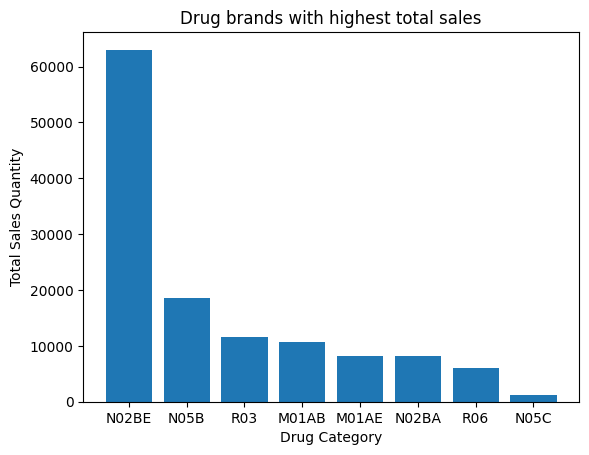

In [61]:
plt.bar(df_res['total_sales'].sort_values(ascending=False).index,
        df_res['total_sales'].sort_values(ascending=False))
plt.title('Drug brands with highest total sales')  # Fixed spelling
plt.xlabel('Drug Category')
plt.ylabel('Total Sales Quantity')
plt.show()

Which three drugs have the highest sales in January 2015, July 2016, September 2017.

In [64]:
filtered_df = df1[(df1["datum"].dt.year == 2015) & (df1['datum'].dt.month == 1)]

col_sum = filtered_df[drug_names].sum()

top_three = col_sum.nlargest(3)

print(top_three)

N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64


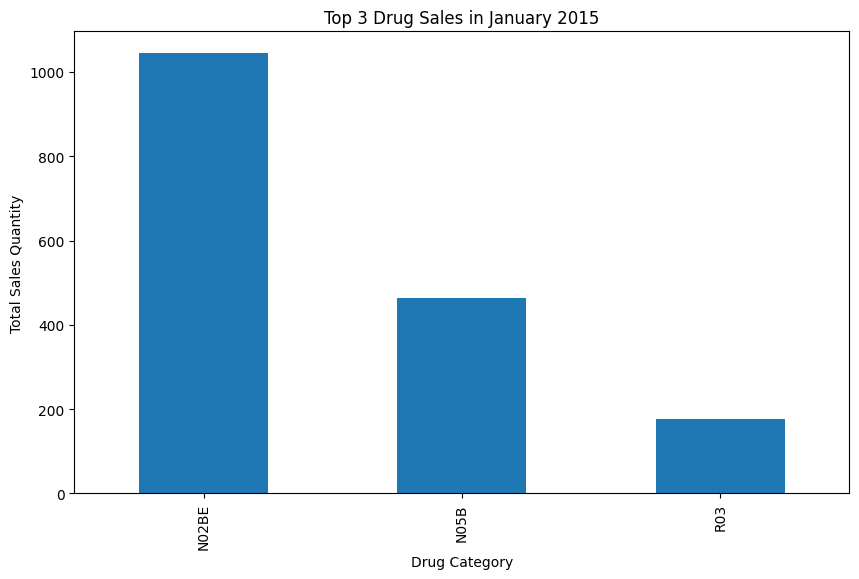

In [71]:
filtered_df[drug_names].sum().sort_values(ascending=False).head(3).plot(kind='bar', figsize=(10, 6))
plt.title(f'Top 3 Drug Sales in January 2015')
plt.xlabel('Drug Category')
plt.ylabel('Total Sales Quantity')
plt.show()

In [ ]:
filtered_jul_df = df1[(df1["datum"].dt.year == 2016) & (df1['datum'].dt.month == 7)]

col_sum1 = filtered_jul_df[drug_names].sum()

top_three1 = col_sum1.nlargest(3)

print(top_three1)

N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64


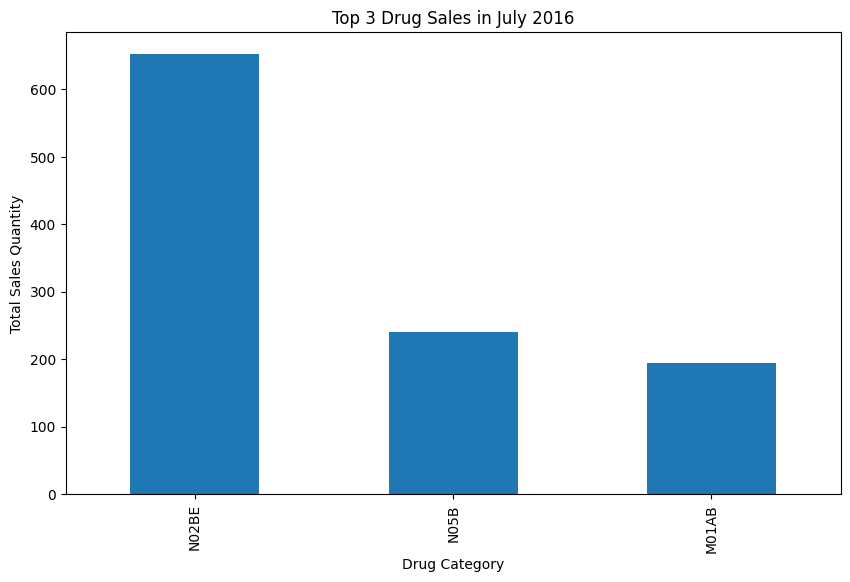

In [72]:
filtered_jul_df[drug_names].sum().sort_values(ascending=False).head(3).plot(kind='bar', figsize=(10, 6))
plt.title(f'Top 3 Drug Sales in July 2016')
plt.xlabel('Drug Category')
plt.ylabel('Total Sales Quantity')
plt.show()

In [ ]:
filtered_sep_df = df1[(df1["datum"].dt.year == 2017) & (df1['datum'].dt.month == 9)]

col_sum2 = filtered_sep_df[drug_names].sum()

top_three2 = col_sum2.nlargest(3)

print(top_three2)

N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


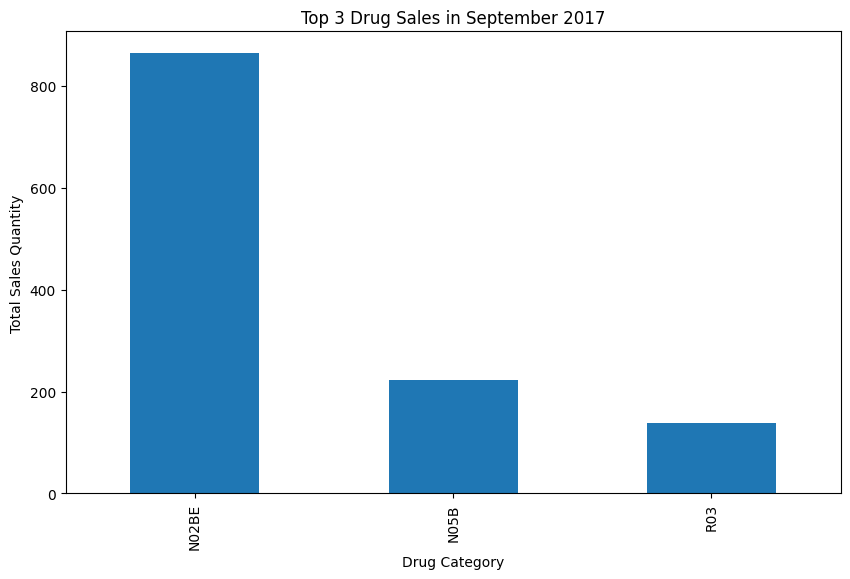

In [73]:
filtered_sep_df[drug_names].sum().sort_values(ascending=False).head(3).plot(kind='bar', figsize=(10, 6))
plt.title(f'Top 3 Drug Sales in September 2017')
plt.xlabel('Drug Category')
plt.ylabel('Total Sales Quantity')
plt.show()


Which drug has sold the most often in 2017?

In [75]:
filter_2017 = df1[(df1['datum'].dt.year == 2017)]
filter_2017[drug_names].sum().idxmax()

'N02BE'

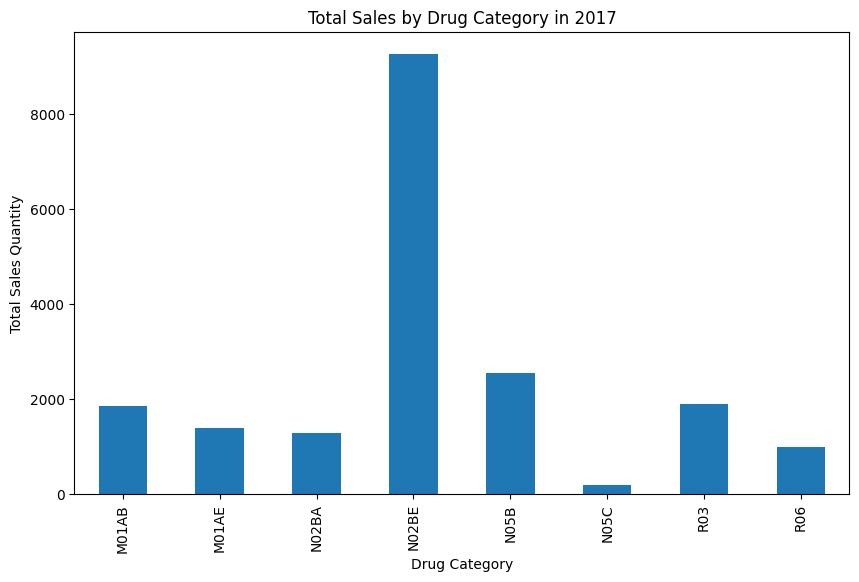

In [78]:
plt.figure(figsize=(10, 6))
filter_2017[drug_names].sum().plot(kind='bar')
plt.title('Total Sales by Drug Category in 2017')
plt.xlabel('Drug Category')
plt.ylabel('Total Sales Quantity')
plt.show()


Which drug category has the highest average daily sales?

In [80]:
df_avg = df1.groupby('datum')[drug_names].sum().mean()

print(f"The drug category with the highest average daily sales is: {df_avg.idxmax()} with an average daily sales of {df_avg.max()}")

The drug category with the highest average daily sales is: N02BE with an average daily sales of 29.917095303105413


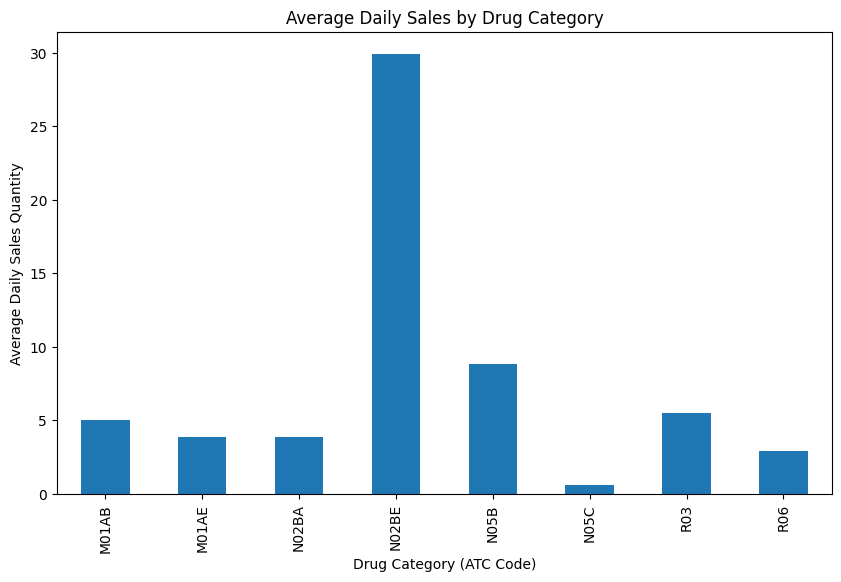

In [81]:
plt.figure(figsize=(10, 6))
df_avg.plot(kind='bar')
plt.title('Average Daily Sales by Drug Category')
plt.xlabel('Drug Category (ATC Code)')
plt.ylabel('Average Daily Sales Quantity')
plt.show()

Are respiratory drugs (R03) sold more during specific months?

In [82]:
r03_monthly_sales = df1.groupby('Month')['R03'].sum()

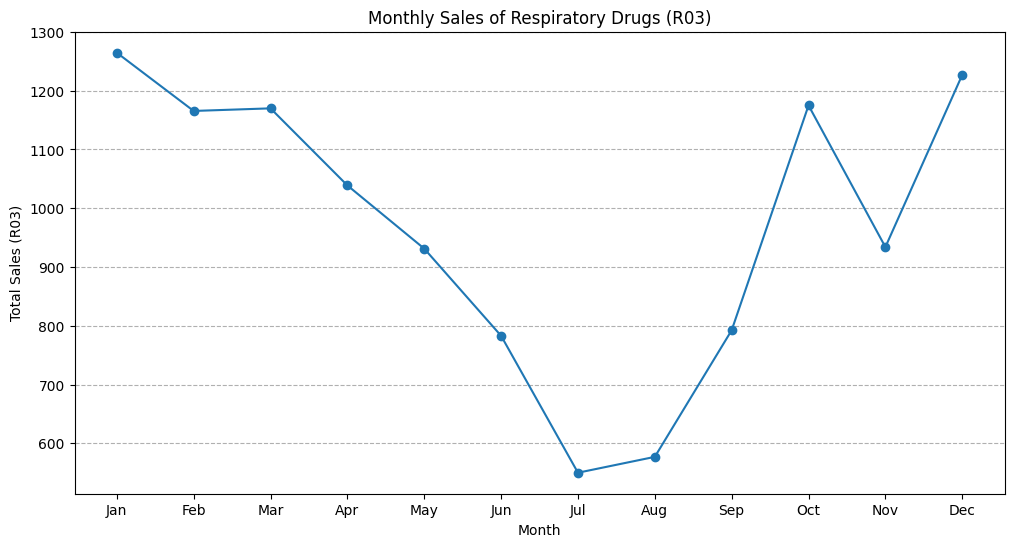

In [83]:

plt.figure(figsize=(12, 6))
r03_monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Sales of Respiratory Drugs (R03)')
plt.xlabel('Month')
plt.ylabel('Total Sales (R03)')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', linestyle='--')
plt.show()